In [166]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# device = torch.device("cpu")
print(device)

cuda


In [167]:
PAD_IDX = 0
SOS_IDX = 1
EOS_IDX = 2
UNK_IDX = 3

In [168]:
import json
def load_jsonl(path):
    df = {"src": [], "tgt": [], "n_clauses": [], "length_bucket": []}
    with open(path, "r") as f:
        lines = f.readlines()
        for line in lines:
            obj = json.loads(line)
            df['src'].append(obj['src'])
            df['tgt'].append(obj['tgt'])
            df['n_clauses'].append(obj['n_clauses'])
            df['length_bucket'].append(obj['length_bucket'])
    return df

In [169]:
df_train = pd.DataFrame(load_jsonl("train.jsonl"))
df_test = pd.DataFrame(load_jsonl("test.jsonl"))
df_val = pd.DataFrame(load_jsonl("val.jsonl"))
len(df_train), len(df_val), len(df_test)

(6000, 800, 800)

In [170]:
df_train.head()

,src,tgt,n_clauses,length_bucket
0,the blue cat throws the blue lamp and the quie...,bigai mouex smaai draol chaun yol bigai lamex ...,3,medium
1,the quiet wizard chases the blue cloud,bluai cloex quiai wizol chaun,1,short
2,the blue bear watches the young flower and the...,braai casex bluai kinol lovun yol oldai casex ...,3,medium
3,the brave queen carries the swift apple,swiai appex braai queol carun,1,short
4,the quiet cat follows the big lamp,bigai lamex quiai catol folun,1,short


In [171]:
df_train['length_bucket'] = df_train['length_bucket'].map({'short': 0, 'medium': 1, 'long': 2})
df_val['length_bucket'] = df_val['length_bucket'].map({'short': 0, 'medium': 1, 'long': 2})
df_test['length_bucket'] = df_test['length_bucket'].map({'short': 0, 'medium': 1, 'long': 2})

In [172]:
df_train['length_bucket'].value_counts()

length_bucket
1    2710
0    1802
2    1488
Name: count, dtype: int64

In [173]:
df_train.iloc[0]

src              the blue cat throws the blue lamp and the quie...
tgt              bigai mouex smaai draol chaun yol bigai lamex ...
n_clauses                                                        3
length_bucket                                                    1
Name: 0, dtype: object

In [174]:
from collections import Counter
c_train = Counter(); c_val = Counter(); c_test = Counter()
c_train.update(df_train['length_bucket'])
c_val.update(df_val['length_bucket'])
c_test.update(df_test['length_bucket'])
print(c_train, c_val, c_test)

Counter({1: 2710, 0: 1802, 2: 1488}) Counter({1: 384, 0: 210, 2: 206}) Counter({1: 366, 0: 242, 2: 192})


In [175]:
MAX_LEN = 50
def preprocess(text):
    return text.lower().split()
class Vocab:
    def __init__(self, texts):
        c = Counter()
        for t in texts:
            c.update(preprocess(t))
        self.word2idx = {"<pad>": PAD_IDX, "<sos>": SOS_IDX, "<eos>": EOS_IDX, "<unk>": UNK_IDX}
        count = len(self.word2idx)
        self.idx2word = {PAD_IDX: "<pad>", SOS_IDX: "<sos>", EOS_IDX: "<eos>", UNK_IDX: "<unk>"}
        for word, _ in sorted(c.items(), key=lambda item: (-item[1], item[0])):
            self.word2idx[word] = count
            self.idx2word[count] = word
            count += 1
    def __len__(self):
        return len(self.word2idx)
    def encode(self, text):
        return [self.word2idx.get(t, UNK_IDX) for t in preprocess(text)]
    def decode(self, ids):
        out = []
        for i in ids:
            tok = self.idx2word[int(i)]
            if tok == "<eos>":
                break
            if tok not in ("<pad>", "<sos>"):
                out.append(tok)
        return " ".join(out)

In [176]:
src_vocab = Vocab(df_train['src'].values)
tgt_vocab = Vocab(df_train['tgt'].values)
len(src_vocab), len(tgt_vocab)

(50, 49)

In [177]:
class TranlationDataset(torch.utils.data.Dataset):
    def __init__(self, frame, src_vocab, tgt_vocab):
        # print("init")
        self.frame = frame.reset_index(drop=True)
        self.src_vocab = src_vocab
        self.tgt_vocab = tgt_vocab
    def __len__(self):
        # print("len")
        return len(self.frame)
    def __getitem__(self, index):
        # print("getitem")
        r = self.frame.iloc[index]
        src_list = [self.src_vocab.word2idx["<sos>"]] + self.src_vocab.encode(r['src'])[:MAX_LEN-2] + [self.src_vocab.word2idx["<eos>"]]
        # src_len = len(src_list)
        # src_list += [self.src_vocab.word2idx["<pad>"]] * (MAX_LEN - src_len)
        src_mask = [1] * len(src_list) + [0] * (MAX_LEN - len(src_list))
        src_mask = torch.tensor(src_mask, dtype=torch.long)
        src_list.extend([PAD_IDX] * (MAX_LEN - len(src_list)))
        src = torch.tensor(
            src_list,
            dtype=torch.long
        )
        tgt_list = [self.tgt_vocab.word2idx["<sos>"]] + self.tgt_vocab.encode(r['tgt'])[:MAX_LEN-2] + [self.tgt_vocab.word2idx["<eos>"]]
        # tgt_len = len(tgt_list)
        # tgt_list += [self.tgt_vocab.word2idx["<pad>"]] * (MAX_LEN - tgt_len)
        tgt_mask = [1] * len(tgt_list) + [0] * (MAX_LEN - len(tgt_list))
        tgt_mask = torch.tensor(tgt_mask, dtype=torch.long)
        tgt_list.extend([PAD_IDX] * (MAX_LEN - len(tgt_list)))
        tgt = torch.tensor(
            tgt_list,
            dtype=torch.long
        )
        # print(src)
        # print(tgt)
        label = torch.tensor(r['length_bucket'], dtype=torch.long)
        return src, tgt, label, src_mask, tgt_mask

In [178]:
data = TranlationDataset(df_train, src_vocab, tgt_vocab)
src, tgt, label, src_mask, tgt_mask = data.__getitem__(0)
src_mask.count_nonzero()

tensor(25)

In [179]:
print(src_mask)

tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0])


In [180]:
src_mask.shape

torch.Size([50])

In [181]:
src_mask.shape

torch.Size([50])

In [182]:
src_mask.unsqueeze(0).shape

torch.Size([1, 50])

In [183]:
# def collate_fn(batch):
#     # print("collate fn")
#     srcs, tgts, label, src_mask, tgt_mask = zip(*batch)
#     src_lens = torch.tensor([x.count_nonzero() for x in src_mask], dtype=torch.long)
#     tgt_lens = torch.tensor([x.count_nonzero() for x in tgt_mask], dtype=torch.long)
#     # print(lens)
#     order = torch.argsort(src_lens, descending=True)
#     # print(order)
#     srcs = [srcs[i] for i in order]
#     tgts = [tgts[i] for i in order]
#     return srcs, tgts, src_lens, tgt_lens, label, src_mask, tgt_mask

In [184]:
def simulate_bptt(w, seq_length=MAX_LEN):
    """
    g_t-1 = w g_t
    """
    # g_maxlen = 1
    g = []
    for i in range(seq_length):
        g.append(w**i)
    return np.array(g[::-1])

In [185]:
simulate_bptt(0.92)

array([0.01681139, 0.01827325, 0.01986222, 0.02158937, 0.02346671,
       0.02550729, 0.02772532, 0.03013622, 0.03275676, 0.03560517,
       0.03870127, 0.0420666 , 0.04572457, 0.04970062, 0.05402241,
       0.05872001, 0.0638261 , 0.06937619, 0.07540891, 0.0819662 ,
       0.0890937 , 0.09684098, 0.10526193, 0.11441514, 0.12436429,
       0.13517857, 0.14693323, 0.15971003, 0.17359786, 0.18869333,
       0.20510144, 0.22293635, 0.24232212, 0.26339361, 0.2862974 ,
       0.31119283, 0.33825308, 0.36766639, 0.39963738, 0.43438845,
       0.47216136, 0.51321887, 0.5578466 , 0.606355  , 0.65908152,
       0.71639296, 0.778688  , 0.8464    , 0.92      , 1.        ])

In [186]:
simulate_bptt(1.08)

array([43.42741899, 40.21057314, 37.23201217, 34.47408534, 31.92044939,
       29.55597166, 27.36664042, 25.33948187, 23.46248322, 21.7245215 ,
       20.11529768, 18.62527563, 17.24562558, 15.96817184, 14.78534429,
       13.69013361, 12.67604964, 11.737083  , 10.86766944, 10.06265689,
        9.3172749 ,  8.62710639,  7.98806147,  7.39635321,  6.8484752 ,
        6.34118074,  5.87146365,  5.43654041,  5.03383372,  4.66095714,
        4.31570106,  3.9960195 ,  3.70001805,  3.42594264,  3.17216911,
        2.93719362,  2.71962373,  2.51817012,  2.331639  ,  2.158925  ,
        1.99900463,  1.85093021,  1.71382427,  1.58687432,  1.46932808,
        1.36048896,  1.259712  ,  1.1664    ,  1.08      ,  1.        ])

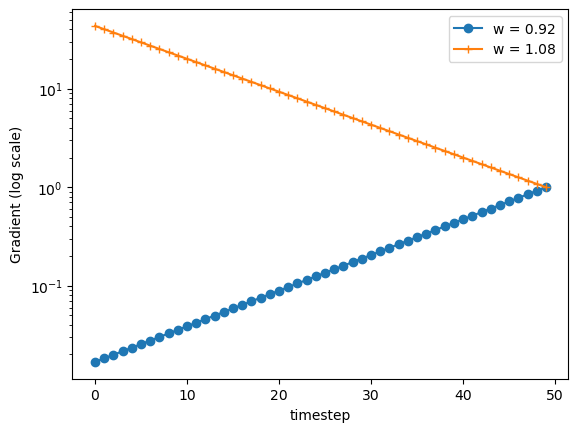

In [187]:
import matplotlib.pyplot as plt
plt.plot(simulate_bptt(0.92), marker='o', label='w = 0.92')
plt.plot(simulate_bptt(1.08), marker='+', label='w = 1.08')
plt.yscale('log')
plt.xlabel('timestep')
plt.ylabel('Gradient (log scale)')
plt.legend()
plt.show()

In [188]:
torch.randn(1, 2)

tensor([[0.3367, 0.1288]])

In [189]:
x = torch.zeros(2, 3)
y = torch.rand(2, 3)
print(x)
print(y)
z = torch.stack([x, y])
print(z)

tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[0.3904, 0.6009, 0.2566],
        [0.7936, 0.9408, 0.1332]])
tensor([[[0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000]],

        [[0.3904, 0.6009, 0.2566],
         [0.7936, 0.9408, 0.1332]]])


In [190]:
import math
class EncoderRNN(nn.Module):
    def __init__(self, d, src_vocab_size):
        super().__init__()
        self.d = d
        self.src_vocab_size = src_vocab_size
        self.emb = nn.Embedding(src_vocab_size, d)
        # Scale weight initialization by 1/sqrt(d)
        self.wxh = nn.Parameter(torch.randn(d, d) / math.sqrt(d))
        self.whh = nn.Parameter(torch.randn(d, d) / math.sqrt(d))
        self.b = nn.Parameter(torch.zeros(d))
        self.activation = nn.Tanh()
    def forward(self, x, mask, h=None, return_history=False):
        """ 
        x => (b, s,) => (b, s, d)
        h => (b, d)
        mask => (b, s,)
        """
        # print(f"Encoder forward: x->{x.shape}, mask->{mask.shape}")
        x = self.emb(x)
        b, s, d = x.shape
        history_list = []
        if h is None:
            # h = torch.zeros(b, d)
            h = torch.zeros(b, d, device=x.device, dtype=x.dtype) # device is crucial
        history = h
        for t in range(s):
            h_1 = self.activation(x[:,t,:] @ self.wxh + h @ self.whh + self.b)
            m_t = mask[:, t, None] # (b, 1)
            h = m_t * h_1 + (1 - m_t) * h
            # h = mask[:, t] * h_1 + (1 - mask[:, t]) * h
            if return_history:
                history_list.append(h)
        if return_history:
            history = torch.stack(history_list, dim=1)
            return h, history
        else:
            return h

In [191]:
a = torch.rand(2, 4)
print(a)
b = a.argmax(dim=1)
print(b)
print(b.shape)

tensor([[0.9346, 0.5936, 0.8694, 0.5677],
        [0.7411, 0.4294, 0.8854, 0.5739]])
tensor([0, 2])
torch.Size([2])


In [192]:
class DecoderRNN(nn.Module):
    def __init__(self, encoder, tgt_vocab_size):
        super().__init__()
        self.encoder = encoder
        d = encoder.d
        self.emb = nn.Embedding(tgt_vocab_size, d)
        self.wxh = nn.Parameter(torch.randn(d, d))
        self.whh = nn.Parameter(torch.randn(d, d))
        self.activation = nn.Tanh()
        self.b = nn.Parameter(torch.randn(d))
        self.proj = nn.Linear(d,tgt_vocab_size, bias=False)
        self.proj.weight = self.emb.weight
    def forward(self, tgt, tgt_mask, src, src_mask, tf=0.5):
        """ 
        tgt => (b, s,)
        h => (b, d)
        mask => (b, d,)
        """
        # print(f"Decoder forward: tgt-> {tgt.shape}, tgt_mask-> {tgt_mask.shape}, src-> {src.shape}, src_mask: {src_mask.shape}")
        tgt = self.emb(tgt)
        b, s, d = tgt.shape
        h = self.encoder(src, src_mask)
        token = tgt[:, 0, :]
        outputs = []
        for t in range(1, s):
            h_1 = self.activation(token @ self.wxh + h @ self.whh + self.b)
            m_t = tgt_mask[:, t, None]
            h = m_t * h_1 + (1 - m_t) * h
            output = self.proj(h) # b, d
            outputs.append(output)
            if random.random() < tf:
                token = tgt[:, t, :]
            else:
                preds = output.argmax(dim=1)
                token = self.emb(preds)
        return torch.stack(outputs, dim=1).to(tgt.device) # b, s-1, d

In [193]:
encoder = EncoderRNN(d=64, src_vocab_size=len(src_vocab))
# U(-1, 1) = 2 U(0, 1) - 1
encoder.whh = torch.nn.Parameter(2 * torch.rand(encoder.d, encoder.d) - 1)
decoder = DecoderRNN(encoder, len(tgt_vocab))
print(encoder)
print(decoder)

EncoderRNN(
  (emb): Embedding(50, 64)
  (activation): Tanh()
)
DecoderRNN(
  (encoder): EncoderRNN(
    (emb): Embedding(50, 64)
    (activation): Tanh()
  )
  (emb): Embedding(49, 64)
  (activation): Tanh()
  (proj): Linear(in_features=64, out_features=49, bias=False)
)


In [194]:
from tqdm import tqdm
def train_epoch(model, loader, optimizer, clip_grad=False):
    model.train()
    total_loss = 0.0
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
    grad_norm_hist = []
    for src, tgt, label, src_mask, tgt_mask in tqdm(loader, desc="calculating train loss"):
        src = src.to(device)
        tgt = tgt.to(device)
        src_mask = src_mask.to(device)
        tgt_mask = tgt_mask.to(device)
        output = model(tgt, tgt_mask, src, src_mask)
        # output = output[:, :-1]
        true_label = tgt[:, 1:]
        output = output.reshape(-1, output.shape[-1])
        true_label = true_label.reshape(-1)
        # print(output.shape, true_label.shape)
        # CrossEntropyLoss expects input is [N, C], target is [N]
        loss = criterion(output, true_label.long())
        total_loss += loss.item()
        loss.backward()
        if clip_grad:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        grad_norm_hist.append(model.encoder.whh.grad.norm())
        optimizer.step()
        optimizer.zero_grad()
    total_loss /= max(1, len(loader))
    return total_loss, torch.stack(grad_norm_hist)

In [195]:
train_loader = torch.utils.data.DataLoader(TranlationDataset(df_train, src_vocab, tgt_vocab), batch_size=64)

In [196]:
len(train_loader)

94

calculating train loss: 100%|██████████| 94/94 [00:08<00:00, 11.24it/s]


Epoch: 1, loss: 17.5067


calculating train loss: 100%|██████████| 94/94 [00:08<00:00, 11.66it/s]


Epoch: 2, loss: 17.4972


calculating train loss: 100%|██████████| 94/94 [00:07<00:00, 11.85it/s]


Epoch: 3, loss: 17.5315


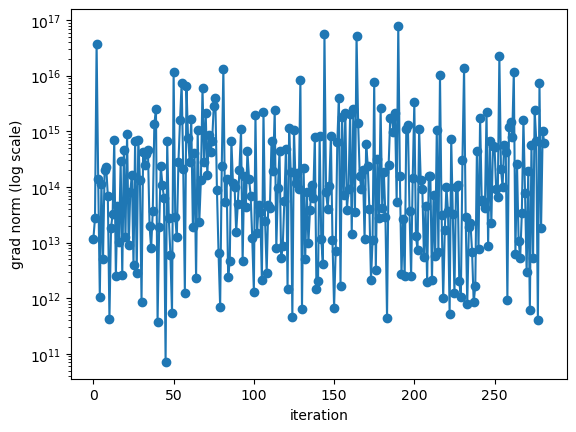

In [197]:
import matplotlib.pyplot as plt
optimizer = torch.optim.Adam(decoder.parameters(), lr=0.001)
NUM_EPOCHS = 3
# encoder.to(device)
decoder.to(device)
grad_norm_hist = []
for epoch in range(NUM_EPOCHS):
    loss, g_norm_hist = train_epoch(decoder, train_loader, optimizer)
    print(f"Epoch: {epoch+1}, loss: {loss:.4f}")
    # print(grad_norm_hist)
    grad_norm_hist.extend(g_norm_hist.cpu())
grad_norm_hist = np.array(grad_norm_hist)
plt.plot(grad_norm_hist, marker='o')
plt.yscale("log")
plt.xlabel("iteration")
plt.ylabel("grad norm (log scale)")
plt.show()

In [198]:
encoder = EncoderRNN(d=64, src_vocab_size=len(src_vocab))
encoder.whh = nn.Parameter(torch.empty(encoder.d, encoder.d))
# Apply orthogonal initialization
nn.init.orthogonal_(encoder.whh)
decoder = DecoderRNN(encoder, len(tgt_vocab))
print(encoder)
print(decoder)

EncoderRNN(
  (emb): Embedding(50, 64)
  (activation): Tanh()
)
DecoderRNN(
  (encoder): EncoderRNN(
    (emb): Embedding(50, 64)
    (activation): Tanh()
  )
  (emb): Embedding(49, 64)
  (activation): Tanh()
  (proj): Linear(in_features=64, out_features=49, bias=False)
)


calculating train loss: 100%|██████████| 94/94 [00:07<00:00, 11.79it/s]


Epoch: 1, loss: 17.1606


calculating train loss: 100%|██████████| 94/94 [00:07<00:00, 11.90it/s]


Epoch: 2, loss: 17.3249


calculating train loss: 100%|██████████| 94/94 [00:07<00:00, 11.80it/s]


...

Epoch: 28, loss: 17.3868


calculating train loss: 100%|██████████| 94/94 [00:07<00:00, 12.01it/s]


Epoch: 29, loss: 17.4063


calculating train loss: 100%|██████████| 94/94 [00:08<00:00, 11.56it/s]


Epoch: 30, loss: 17.4362


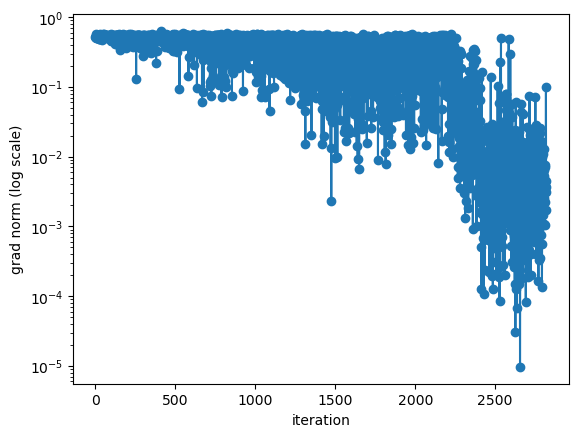

In [199]:
optimizer = torch.optim.Adam(decoder.parameters(), lr=0.001)
NUM_EPOCHS = 30
# encoder.to(device)
decoder.to(device)
grad_norm_hist = []
for epoch in range(NUM_EPOCHS):
    loss, g_norm_hist = train_epoch(decoder, train_loader, optimizer, clip_grad=True)
    print(f"Epoch: {epoch+1}, loss: {loss:.4f}")
    # print(grad_norm_hist)
    grad_norm_hist.extend(g_norm_hist.cpu())
grad_norm_hist = np.array(grad_norm_hist)
plt.plot(grad_norm_hist, marker='o')
plt.yscale("log")
plt.xlabel("iteration")
plt.ylabel("grad norm (log scale)")
plt.show()

In [200]:
import nltk
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

@torch.no_grad()
def greedy_decode(model, src, src_mask, max_len=MAX_LEN):
    """
    Free-running (no teacher forcing) greedy decoding.
    model : a trained DecoderRNN (its .encoder is used to get h0)
    src, src_mask : (b, s) source ids / mask
    Returns: (b, max_len) tensor of predicted target ids (0 = <pad> after <eos>)
    """
    model.eval()
    b = src.shape[0]
    h = model.encoder(src, src_mask)                 # encoder final hidden state -> decoder h0
    token_id = torch.full((b,), SOS_IDX, dtype=torch.long, device=src.device)
    token = model.emb(token_id)                       # embedded <sos>
    finished = torch.zeros(b, dtype=torch.bool, device=src.device)
    out_ids = torch.full((b, max_len), PAD_IDX, dtype=torch.long, device=src.device)

    for t in range(1, max_len):
        h_1 = model.activation(token @ model.wxh + h @ model.whh + model.b)
        h = h_1  # no mask here: every position is "real" until a sequence finishes
        logits = model.proj(h)
        preds = logits.argmax(dim=1)
        # once a sequence has emitted <eos>, keep padding it instead of decoding further
        preds = torch.where(finished, torch.full_like(preds, PAD_IDX), preds)
        out_ids[:, t] = preds
        finished = finished | (preds == EOS_IDX)
        token = model.emb(preds)
        if finished.all():
            break
    return out_ids

In [201]:
BATCH_SIZE = 64

test_dataset = TranlationDataset(df_test, src_vocab, tgt_vocab)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

bucket_names = {0: "short", 1: "medium", 2: "long"}
hyps_by_bucket = {0: [], 1: [], 2: []}
refs_by_bucket = {0: [], 1: [], 2: []}

decoder.eval()
row = 0
with torch.no_grad():
    for src, tgt, label, src_mask, tgt_mask in tqdm(test_loader, desc="Greedy decoding test set"):
        src = src.to(device)
        src_mask = src_mask.to(device)

        pred_ids = greedy_decode(decoder, src, src_mask, max_len=MAX_LEN).cpu()
        bsz = src.shape[0]

        for i in range(bsz):
            hyp_tokens = tgt_vocab.decode(pred_ids[i].tolist()).split()
            ref_tokens = preprocess(df_test.iloc[row]["tgt"])  # raw ground-truth text, whitespace tokenized
            bucket = int(label[i].item())

            hyps_by_bucket[bucket].append(hyp_tokens)
            refs_by_bucket[bucket].append([ref_tokens])  # corpus_bleu expects a list of references per hypothesis
            row += 1

smoothie = SmoothingFunction().method4
bleu_scores = {}
for b in (0, 1, 2):
    name = bucket_names[b]
    if len(hyps_by_bucket[b]) == 0:
        bleu_scores[name] = float("nan")
        continue
    bleu_scores[name] = corpus_bleu(refs_by_bucket[b], hyps_by_bucket[b], smoothing_function=smoothie)

bleu_table = pd.DataFrame({
    "length_bucket": ["short", "medium", "long"],
    "n_examples": [len(hyps_by_bucket[0]), len(hyps_by_bucket[1]), len(hyps_by_bucket[2])],
    "corpus_BLEU": [bleu_scores["short"], bleu_scores["medium"], bleu_scores["long"]],
})
bleu_table

Greedy decoding test set: 100%|██████████| 13/13 [00:00<00:00, 18.90it/s]


,length_bucket,n_examples,corpus_BLEU
0,short,242,0.002085
1,medium,366,0.000271
2,long,192,0.000012


In [202]:
qual_examples = [
    {
        "bucket": "Short",
        "src": "the old girl chases the red ball",
        "tgt": "redai balex oldai girol chaun",
    },
    {
        "bucket": "Medium",
        "src": "the old wizard throws the brave table and the blue fox finds the brave ball",
        "tgt": "braai balex bluai foxol finun yol braai tabex oldai wizol thrun",
    },
    {
        "bucket": "Long",
        "src": "the old dog finds the blue book and the swift cat sees the blue mountain and the small robot follows the old lamp and the young dog greets the quiet cloud",
        "tgt": "quiai cloex youai dogol greun yol oldai lamex smaai robol folun yol bluai mouex swiai catol seeun yol bluai booex oldai dogol finun",
    },
]

def encode_source(sentence, vocab, max_len=MAX_LEN):
    ids = [vocab.word2idx["<sos>"]] + vocab.encode(sentence)[:max_len - 2] + [vocab.word2idx["<eos>"]]
    mask = [1] * len(ids) + [0] * (max_len - len(ids))
    ids = ids + [PAD_IDX] * (max_len - len(ids))
    return (torch.tensor(ids, dtype=torch.long).unsqueeze(0),
            torch.tensor(mask, dtype=torch.long).unsqueeze(0))

decoder.eval()
with torch.no_grad():
    for ex in qual_examples:
        src_ids, src_mask = encode_source(ex["src"], src_vocab)
        src_ids, src_mask = src_ids.to(device), src_mask.to(device)

        pred_ids = greedy_decode(decoder, src_ids, src_mask, max_len=MAX_LEN)
        pred_text = tgt_vocab.decode(pred_ids[0].tolist())

        print(f"--- {ex['bucket']} ---")
        print(f"Source:       {ex['src']}")
        print(f"Ground Truth: {ex['tgt']}")
        print(f"Prediction:   {pred_text}")
        print()

--- Short ---
Source:       the old girl chases the red ball
Ground Truth: redai balex oldai girol chaun
Prediction:   queol

--- Medium ---
Source:       the old wizard throws the brave table and the blue fox finds the brave ball
Ground Truth: braai balex bluai foxol finun yol braai tabex oldai wizol thrun
Prediction:   queol

--- Long ---
Source:       the old dog finds the blue book and the swift cat sees the blue mountain and the small robot follows the old lamp and the young dog greets the quiet cloud
Ground Truth: quiai cloex youai dogol greun yol oldai lamex smaai robol folun yol bluai mouex swiai catol seeun yol bluai booex oldai dogol finun
Prediction:   queol



In [203]:
eps = 1e-8
bleu_short = bleu_scores["short"]
bleu_medium = bleu_scores["medium"]
bleu_long = bleu_scores["long"]

delta_short_long = bleu_short - bleu_long
R_long = bleu_long / (bleu_short + eps)

print(f"BLEU_short  = {bleu_short:.4f}")
print(f"BLEU_medium = {bleu_medium:.4f}")
print(f"BLEU_long   = {bleu_long:.4f}")
print()
print(f"Delta_short-long = BLEU_short - BLEU_long = {delta_short_long:.4f}")
print(f"R_long           = BLEU_long / (BLEU_short + eps) = {R_long:.4f}")

if delta_short_long > 0:
    print("\nBLEU drops as sentences get longer: the fixed-size Seq2Seq bottleneck loses more "
          "information the more clauses it has to compress into a single hidden vector, so the "
          "decoder has a harder time reconstructing long-range structure.")

BLEU_short  = 0.0021
BLEU_medium = 0.0003
BLEU_long   = 0.0000

Delta_short-long = BLEU_short - BLEU_long = 0.0021
R_long           = BLEU_long / (BLEU_short + eps) = 0.0058

BLEU drops as sentences get longer: the fixed-size Seq2Seq bottleneck loses more information the more clauses it has to compress into a single hidden vector, so the decoder has a harder time reconstructing long-range structure.
